# Rossmann Sales Forecasting
## 02 — Exploratory Data Analysis

Explore the main patterns in daily store sales and the relationships for forecasting.

### 1. Load and prepare data

Store metadata is merged with daily sales so store characteristics can be compared with sales.

In [11]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("../data/raw")

train = pd.read_csv(
    data_dir / "train.csv", dtype={"StateHoliday": "string"}, parse_dates=["Date"]
)
test = pd.read_csv(
    data_dir / "test.csv", dtype={"StateHoliday": "string"}, parse_dates=["Date"]
)
store = pd.read_csv(data_dir / "store.csv")

data = train.merge(store, on="Store", how="left", validate="many_to_one")
data = data.sort_values(["Date", "Store"])
open_data = data[data["Open"] == 1].copy()

print("Train:", train.shape)
print("Test:", test.shape)
print("Merged:", data.shape)
print("Training dates:", data["Date"].min().date(), "to", data["Date"].max().date())
print("Unmatched store metadata:", data["StoreType"].isna().sum())

Train: (1017209, 9)
Test: (41088, 8)
Merged: (1017209, 18)
Training dates: 2013-01-01 to 2015-07-31
Unmatched store metadata: 0


### 2. Key data-quality checks

Missing store-days are not confirmed closed days. Historical customers are excluded from future forecasting because their values are unavailable in the test data.

In [12]:
coverage = data.groupby("Store")["Date"].agg(["min", "max", "nunique"])
expected_days = (coverage["max"] - coverage["min"]).dt.days + 1
missing_days = expected_days - coverage["nunique"]

print("Stores with internal date gaps:", (missing_days > 0).sum())
print("Closed days with positive sales:",
      ((data["Open"] == 0) & (data["Sales"] > 0)).sum())
print("Open days with zero sales:",
      ((data["Open"] == 1) & (data["Sales"] == 0)).sum())
print("Missing competition distances:", store["CompetitionDistance"].isna().sum())
print("Missing competition start years:", store["CompetitionOpenSinceYear"].isna().sum())
print("Missing Open values in test:", test["Open"].isna().sum())
print("Train-only columns:", sorted(set(train.columns) - set(test.columns)))

Stores with internal date gaps: 180
Closed days with positive sales: 0
Open days with zero sales: 54
Missing competition distances: 3
Missing competition start years: 354
Missing Open values in test: 11
Train-only columns: ['Customers', 'Sales']


### 3. Missing calendar days by store

Check for  stores having missing dates within their recorded history. These are missing observations, not confirmed closed days, and should not be replaced with zero sales.

Total missing store-days: 33120


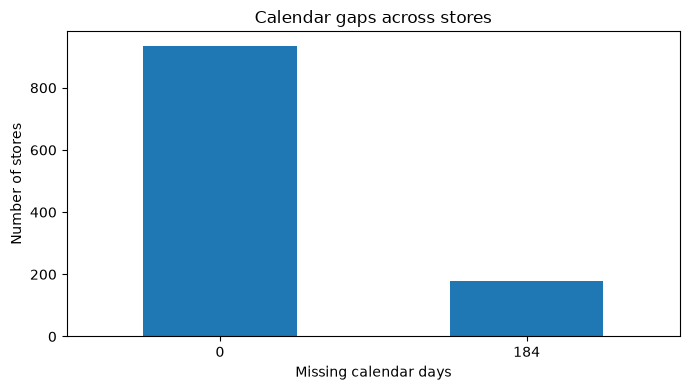

In [13]:
gap_counts = missing_days.value_counts().sort_index()

print("Total missing store-days:", missing_days.sum())

gap_counts.plot.bar(
    figsize=(7, 4),
    rot=0,
    title="Calendar gaps across stores"
)

plt.xlabel("Missing calendar days")
plt.ylabel("Number of stores")
plt.tight_layout()
plt.show()

### 4. Distribution of sales

count    844392.000000
mean       6955.514291
std        3104.214680
min           0.000000
50%        6369.000000
90%       10771.000000
99%       17789.000000
max       41551.000000
Name: Sales, dtype: float64


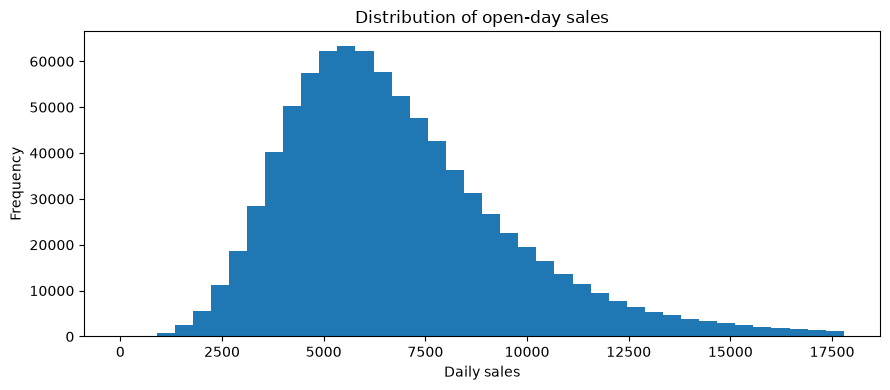

In [14]:
print(open_data["Sales"].describe(percentiles=[0.5, 0.9, 0.99]))

sales_limit = open_data["Sales"].quantile(0.99)
sales_plot = open_data.loc[open_data["Sales"] <= sales_limit, "Sales"]

sales_plot.plot.hist(bins=40, figsize=(9, 4), title="Distribution of open-day sales")
plt.xlabel("Daily sales")
plt.tight_layout()
plt.show()

Open-day sales are right-skewed. The plot is limited to the 99th percentile for readability; higher sales observations remain in the data.

### 5. Sales trend over time

Weekly averages reveal changing sales levels and seasonal peaks. Changes in store coverage may also affect the overall average.

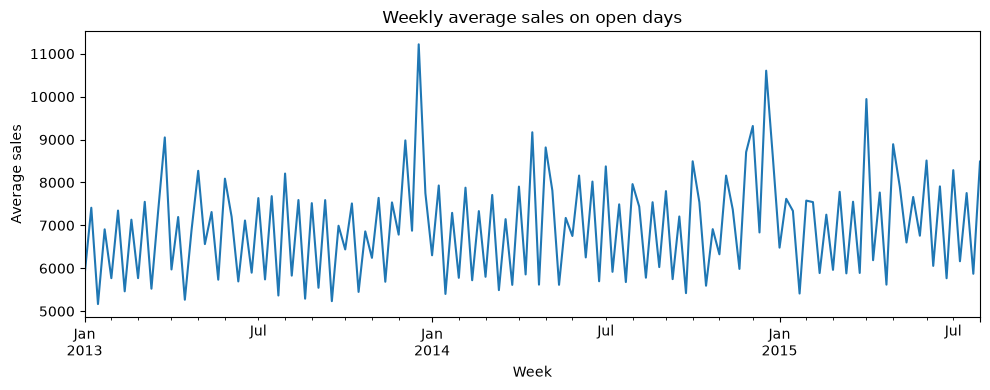

In [15]:
weekly_sales = open_data.groupby(pd.Grouper(key="Date", freq="W"))["Sales"].mean()

weekly_sales.plot(figsize=(10, 4), title="Weekly average sales on open days")
plt.ylabel("Average sales")
plt.xlabel("Week")
plt.tight_layout()
plt.show()

### 6. Monthly seasonality

December has higher average open-day sales in the two complete years. The 2014 coverage gap and partial 2015 period should be considered when comparing years.

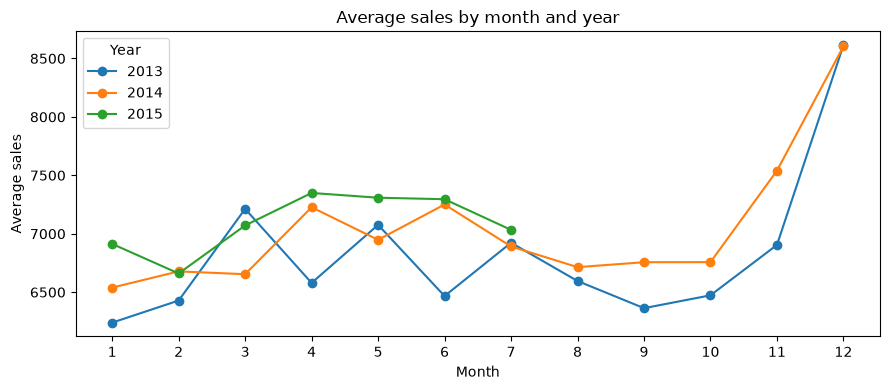

In [16]:
open_data["Year"] = open_data["Date"].dt.year
open_data["Month"] = open_data["Date"].dt.month

monthly_sales = open_data.groupby(["Month", "Year"])["Sales"].mean().unstack()

monthly_sales.plot(marker="o", figsize=(9, 4), title="Average sales by month and year")
plt.xlabel("Month")
plt.ylabel("Average sales")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.tight_layout()
plt.show()

### 7. Promotions and weekdays



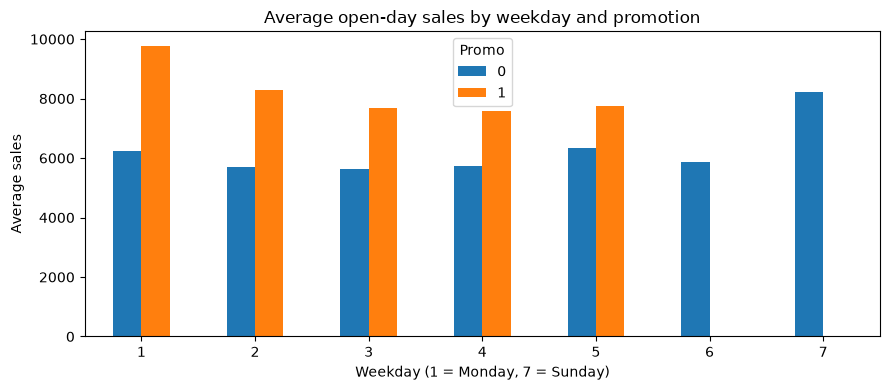

In [17]:
promo_weekday = open_data.groupby(["DayOfWeek", "Promo"])["Sales"].mean().unstack()

promo_weekday.plot.bar(figsize=(9, 4), rot=0,
                       title="Average open-day sales by weekday and promotion")
plt.xlabel("Weekday (1 = Monday, 7 = Sunday)")
plt.ylabel("Average sales")
plt.legend(title="Promo")
plt.tight_layout()
plt.show()

Average sales differ by both weekday and promotion status.

### 8. Store characteristics


Number of stores by category:


Assortment,a,b,c
StoreType,,,
a,381,0,221
b,7,9,1
c,77,0,71
d,128,0,220


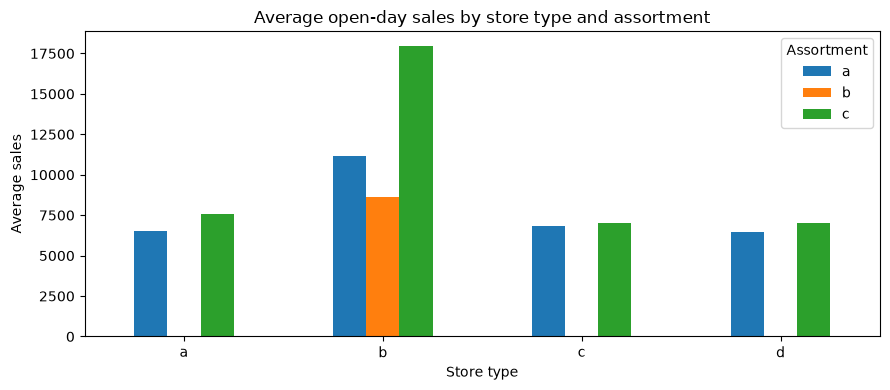

In [18]:
store_groups = open_data.groupby(["StoreType", "Assortment"])["Sales"].mean().unstack()
store_counts = store.groupby(["StoreType", "Assortment"]).size().unstack(fill_value=0)

print("Number of stores by category:")
display(store_counts)

store_groups.plot.bar(figsize=(9, 4), rot=0,
                      title="Average open-day sales by store type and assortment")
plt.xlabel("Store type")
plt.ylabel("Average sales")
plt.legend(title="Assortment")
plt.tight_layout()
plt.show()

Store type and assortment show different average sales levels. Some categories contain very few stores, so the group sizes matter.

### 9. Competition distance and sales

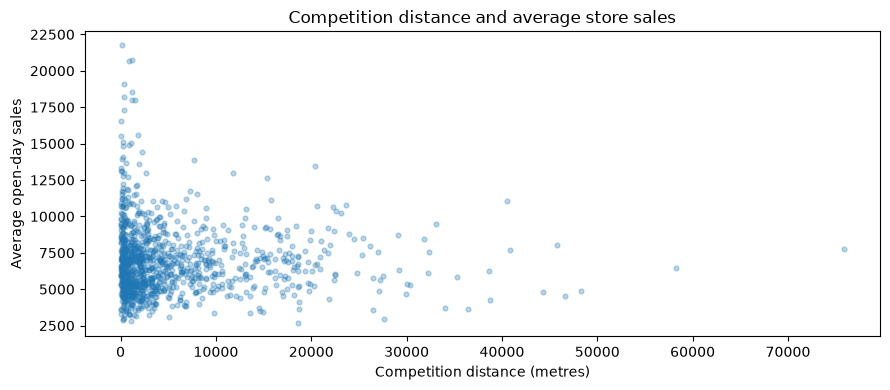

In [19]:
store_sales = open_data.groupby("Store")["Sales"].mean()
competition = store[["Store", "CompetitionDistance"]].merge(
    store_sales.rename("AverageSales"), on="Store", how="left"
)

competition.plot.scatter(x="CompetitionDistance", y="AverageSales",
                         alpha=0.3, s=12, figsize=(9, 4),
                         title="Competition distance and average store sales")
plt.xlabel("Competition distance (metres)")
plt.ylabel("Average open-day sales")
plt.tight_layout()
plt.show()

Store-average sales vary considerably at similar competition distances. 

### 10. Historical sales patterns — Autocorrelation
Autocorrelation was examined for Store 1 to identify potential historical sales features. Only data before the validation periods was used.

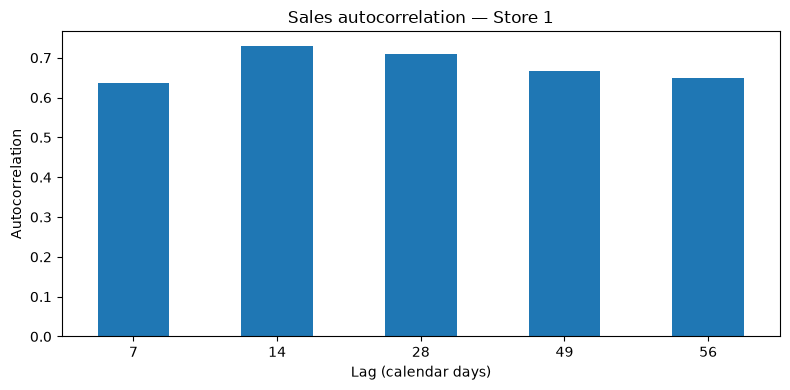

In [20]:
# Use dates before the two 48-day validation windows.
cutoff = train["Date"].max() - pd.Timedelta(days=96)
example = data[(data["Store"] == 1) & (data["Date"] <= cutoff)]
example_sales = example.set_index("Date")["Sales"].asfreq("D")

lags = [7, 14, 28, 49, 56]
correlations = []
for lag in lags:
    correlations.append(example_sales.autocorr(lag=lag))

pd.Series(correlations, index=lags).plot.bar(
    figsize=(8, 4), rot=0, title="Sales autocorrelation — Store 1"
)
plt.xlabel("Lag (calendar days)")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

Store 1 showed positive autocorrelation across all examined lags, with the strongest relationships at 14 and 28 days. Lags 49 and 56 also showed positive relationships and were considered for feature engineering because their historical sales values remain available throughout the 48-day forecast horizon.

### 11. EDA summary

Sales show weekly and monthly patterns, differences across store categories, and associations with promotions. Competition distance has no clear simple relationship with sales in this comparison. Historical lags are candidates rather than proven predictors.

The calendar-gap chart identifies stores with incomplete daily records. For forecasting, preserve missing store-days, separate confirmed closures from unknown opening status, and avoid using future `Customers` or sales. Model performance will be assessed using chronological 48-day validation windows.